# 02 - Comparing different estimators on SPY

This notebook compares different estimators defined on SPY.

The 4 estimators we will discuss are: close-to-close, Parkinson and Garman–Klass (with and without the overnight term).

In [21]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../src")
import numpy as np, pandas as pd
from volforecast.data import load
from volforecast.estimators import daily_variance, annualize, overnight, close_to_close

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Daily variance estimates

In [22]:
spy = load("SPY")
estimators = {"cc": daily_variance(spy, "cc"), "parkinson": daily_variance(spy, "parkinson"), "gk": daily_variance(spy),
              "gk_intraday": daily_variance(spy, include_overnight=False)}
est = pd.DataFrame(estimators)
est

,cc,parkinson,gk,gk_intraday
Date,,,,
2007-01-03,NaN,NaN,NaN,0.000116
2007-01-04,4.493371e-06,0.000038,0.000049,0.000048
2007-01-05,6.413280e-05,0.000025,0.000020,0.000014
2007-01-08,2.129426e-05,0.000028,0.000035,0.000031
2007-01-09,7.229967e-07,0.000027,0.000036,0.000035
...,...,...,...,...
2026-11-10,1.359359e-05,0.000074,0.000085,0.000045
2026-11-11,1.716595e-04,0.000120,0.000128,0.000044
2026-11-12,1.257868e-05,0.000114,0.000129,0.000070


## 21-day volatility

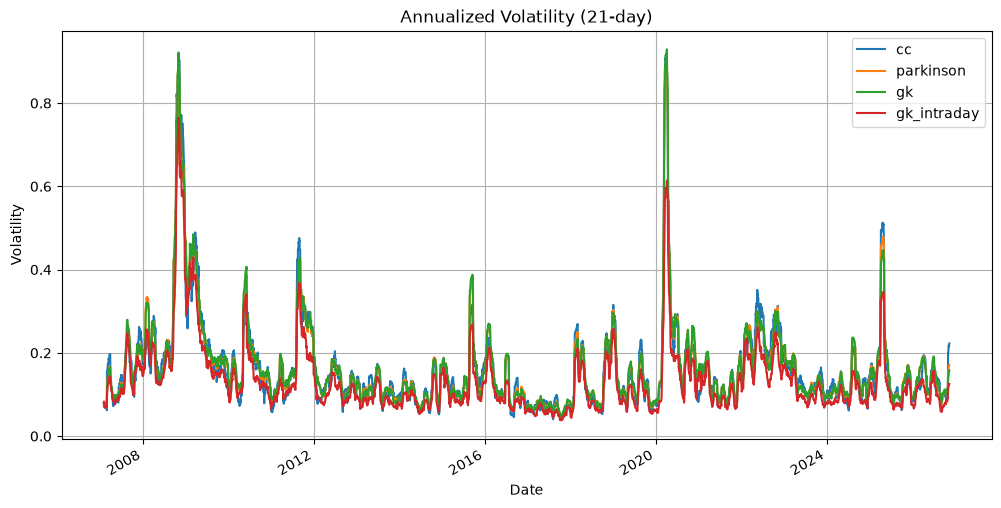

In [27]:
ax = annualize(est.rolling(21).mean()).plot(title="Annualized Volatility (21-day)", figsize=(12, 6), grid=True, xlabel="Date", ylabel="Volatility")
ax.figure.savefig("../figures/spy_vol_estimators.png", dpi=150, bbox_inches="tight")

**Why average variance, not volatility (Jensen's inequality)**

`annualize` takes a square root, and $\sqrt{\cdot}$ is concave. Jensen's inequality says that for a concave $f$, $\mathbb{E}[f(X)] \le f(\mathbb{E}[X])$. So

$$\underbrace{\tfrac{1}{21}\sum \sqrt{252\,\sigma_t^2}}_{\texttt{annualize(est).rolling(21).mean()}} \;\le\; \underbrace{\sqrt{252 \cdot \tfrac{1}{21}\sum \sigma_t^2}}_{\texttt{annualize(est.rolling(21).mean())}}$$

Variance is additive over time, so averaging daily variances and then taking the root gives the volatility over the 21-day window. Averaging daily vols first is biased downward. The gap grows with how noisy the daily estimates are, so it is largest for `cc` (a single squared return) and smallest for the range-based estimators.

In [24]:
vol_of_mean = annualize(est.rolling(21).mean())   # correct: sqrt of mean variance
mean_of_vol = annualize(est).rolling(21).mean()   # biased low by Jensen
(vol_of_mean - mean_of_vol).mean().rename("avg gap (vol pts)")

cc             0.035622
parkinson      0.014923
gk             0.014591
gk_intraday    0.011059
Name: avg gap (vol pts), dtype: float64

## Summary numbers

In [25]:
annualize(est.mean()).rename('avg annualized vol')

cc             0.195684
parkinson      0.196427
gk             0.198180
gk_intraday    0.158667
Name: avg annualized vol, dtype: float64

As we can see, the different estimators agree on average (around 19.6%), except gk_intraday, which is much lower (15.9%). To explain this, we will look at the share of the overnight move in the close-to-close estimator.

In [28]:
print(f"overnight share of variance: {overnight(spy).mean() / close_to_close(spy).mean():.1%}")

overnight share of variance: 36.8%


On average, 37% of the variance comes from the overnight move.